In [15]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint


# ============================================================
# 1. DATASET PATH
# ============================================================

train_dir = "/kaggle/input/datasets/winminoolol/question-dataset/train"
val_dir   = "/kaggle/input/datasets/winminoolol/question-dataset/val"


# ============================================================
# 2. SETTINGS
# ============================================================

IMG_SIZE = (128, 128)
BATCH_SIZE = 64
SEED = 42


# ============================================================
# 3. LOAD TRAINING DATA
# ============================================================

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)


# ============================================================
# 4. LOAD VALIDATION DATA
# ============================================================

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)


# ============================================================
# 5. CLASS NAMES / IDS
# ============================================================

class_names = train_ds.class_names

num_classes = len(class_names)

print("Number of classes:", num_classes)
print("IDs:", class_names)


# ============================================================
# 6. PERFORMANCE
# ============================================================

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

Found 100 files belonging to 10 classes.
Found 150 files belonging to 10 classes.
Number of classes: 10
IDs: ['s01', 's02', 's03', 's04', 's05', 's06', 's07', 's08', 's09', 's10']


Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_12 (Rescaling)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_36 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_37 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_38 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_38 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_17 (Flatten)            │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,557,834 (25.02 MB)

 Trainable params: 6,557,834 (25.02 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 13s 6s/step - accuracy: 0.0500 - loss: 2.3197 - val_accuracy: 0.1000 - val_loss: 2.2778
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 527ms/step - accuracy: 0.1100 - loss: 2.2961 - val_accuracy: 0.2133 - val_loss: 2.2586
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 500ms/step - accuracy: 0.2100 - loss: 2.2457 - val_accuracy: 0.2533 - val_loss: 2.2188
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 296ms/step - accuracy: 0.1900 - loss: 2.2043 - val_accuracy: 0.2267 - val_loss: 2.1118
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 673ms/step - accuracy: 0.2700 - loss: 2.0484 - val_accuracy: 0.3667 - val_loss: 1.9318
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 550ms/step - accuracy: 0.3900 - loss: 1.8962 - val_accuracy: 0.5067 - val_loss: 1.7054
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 540ms/step - accuracy: 0.5000 - loss: 1.6400 - val_accuracy: 0.6067 - val_loss: 1.3874
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 594ms/step - accuracy: 0.5600 - loss: 1.3996 - val_accuracy: 0.6400 - val_loss: 1

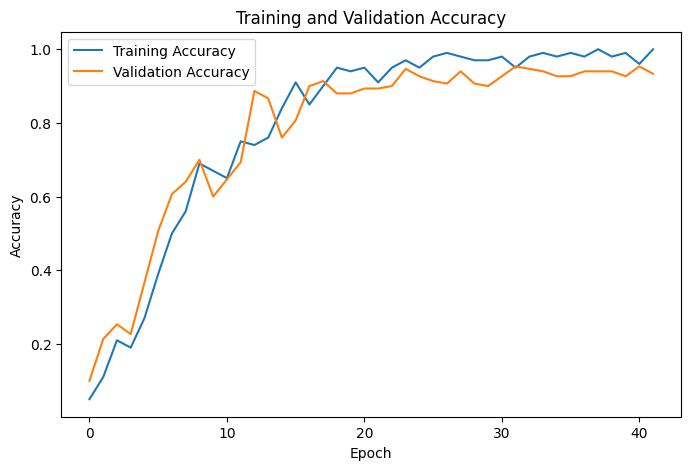

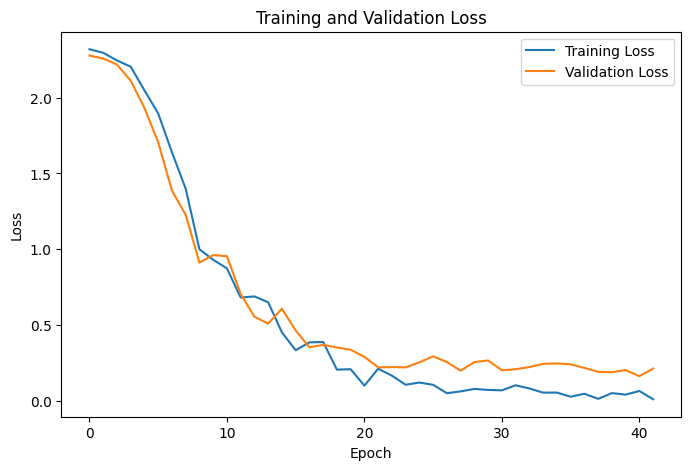

Model saved: /kaggle/working/cnn_face_id_model.keras
Model loaded successfully!


In [16]:

# ============================================================
# 7. CNN MODEL
# ============================================================

model = models.Sequential([
    
    layers.Input(shape=(128, 128, 3)),
    
    # Normalize
    layers.Rescaling(1./255),
    
    # Conv Layer 1
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Conv Layer 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Conv Layer 3
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Flatten
    layers.Flatten(),
    
    # Dense Layer 1
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.6),

    # Dense Layer 2
    layers.Dense(128, activation='relu'),

    # Dense Layer 3
    layers.Dense(64, activation='relu'),

    # Output Layer
    layers.Dense(num_classes, activation='softmax')
])


# ============================================================
# 8. MODEL SUMMARY
# ============================================================

model.summary()


# ============================================================
# 9. COMPILE
# ============================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


# ============================================================
# 10. CALLBACKS
# ============================================================

callbacks = [

    EarlyStopping(
        monitor='val_accuracy',
        patience=10,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        "/kaggle/working/best_cnn_model.keras",
        monitor='val_accuracy',
        save_best_only=True
    )
]


# ============================================================
# 11. TRAIN
# ============================================================

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=callbacks
)


# ============================================================
# 12. EVALUATION
# ============================================================

train_loss, train_acc = model.evaluate(
    train_ds,
    verbose=0
)

val_loss, val_acc = model.evaluate(
    val_ds,
    verbose=0
)

print()
print("======================================")
print(f"Training Accuracy   : {train_acc * 100:.2f}%")
print(f"Validation Accuracy : {val_acc * 100:.2f}%")
print("======================================")


# ============================================================
# 13. ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()


# ============================================================
# 14. LOSS GRAPH
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()


# ============================================================
# 15. SAVE MODEL
# ============================================================

model_path = "/kaggle/working/cnn_face_id_model.keras"

model.save(model_path)

print("Model saved:", model_path)


# ============================================================
# 16. LOAD MODEL
# ============================================================

loaded_model = tf.keras.models.load_model(model_path)

print("Model loaded successfully!")



Enter the path of the image to predict:  /kaggle/input/datasets/winminoolol/question-dataset/val/s01/11_jpg.rf.eb44e0f3d6c1b9b5e6ce087a0a5504b5.jpg


Selected image: /kaggle/input/datasets/winminoolol/question-dataset/val/s01/11_jpg.rf.eb44e0f3d6c1b9b5e6ce087a0a5504b5.jpg

INFERENCE RESULT
Image Path   : /kaggle/input/datasets/winminoolol/question-dataset/val/s01/11_jpg.rf.eb44e0f3d6c1b9b5e6ce087a0a5504b5.jpg
Predicted ID : s01
Confidence   : 98.38%


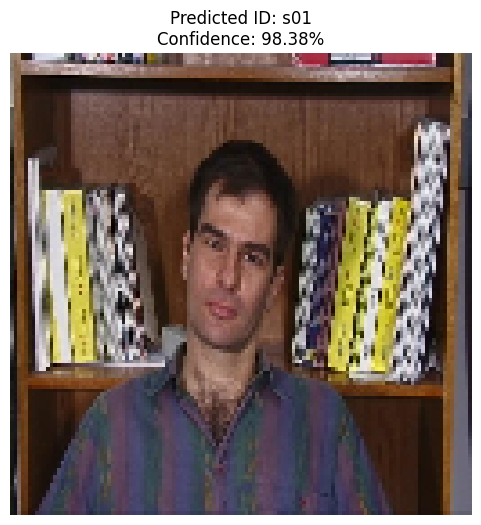

In [18]:
# ============================================================
# 17. INPUT IMAGE PATH
# ============================================================

input_image_path = input(
    "Enter the path of the image to predict: "
).strip()

print("Selected image:", input_image_path)


# ============================================================
# 18. CHECK IMAGE PATH
# ============================================================

if not os.path.exists(input_image_path):
    print("ERROR: Image path does not exist!")
else:

    # ========================================================
    # 19. LOAD IMAGE
    # ========================================================

    img = image.load_img(
        input_image_path,
        target_size=IMG_SIZE
    )

    img_array = image.img_to_array(img)

    # Add batch dimension
    img_batch = np.expand_dims(
        img_array,
        axis=0
    )


    # ========================================================
    # 20. PREDICT
    # ========================================================

    predictions = loaded_model.predict(
        img_batch,
        verbose=0
    )

    # Get class with highest probability
    predicted_index = np.argmax(
        predictions[0]
    )

    # Convert class index to ID
    predicted_id = class_names[
        predicted_index
    ]

    # Prediction confidence
    confidence = predictions[0][
        predicted_index
    ]


    # ========================================================
    # 21. PRINT RESULT
    # ========================================================

    print()
    print("======================================")
    print("INFERENCE RESULT")
    print("======================================")
    print("Image Path   :", input_image_path)
    print("Predicted ID :", predicted_id)
    print(f"Confidence   : {confidence * 100:.2f}%")
    print("======================================")


    # ========================================================
    # 22. VISUALIZE IMAGE + PREDICTION
    # ========================================================

    plt.figure(figsize=(6, 6))

    plt.imshow(img)

    plt.axis("off")

    plt.title(
        f"Predicted ID: {predicted_id}\n"
        f"Confidence: {confidence * 100:.2f}%"
    )

    plt.show()